# Crystal-field tomography, 2D toy, per-voxel sub-block multislice
Each 2 A voxel holds a 7 x 7 block of fine potential (0.29 A sub-pixels). The forward model rotates the tiled blocks, runs multislice, applies the defocus and bins to the 2 A pixel, so the flicker comes from the same physics as the data. Every tenth tilt is held out. Inversions come from `run_ms.py`.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import torch
from scipy.ndimage import gaussian_filter

sys.path.insert(0, str(Path.cwd()))

from quantem.core.visualization.visualization import show_2d

import sim2d
from invert_ms import SubMS, flicker_power, true_object

## Data
Twinned particle of one phase with an amorphous cap at the same density, and the same particle without the cap.

In [2]:
sim2d.main("fewAm")
sim2d.main("fewA")
sims = {kind: np.load(f"runs/sim_{kind}.npz") for kind in ["fewAm", "fewA"]}
runs = {
    "fewAm": {
        "mean potential only": "coarse",
        "sub-blocks, complex": "complex",
        "density + free flicker": "split",
        "density + complex flicker": "split_complex",
        "sub-blocks, U >= 0": "positive",
        "sub-blocks, U >= -0.5 density": "floor05",
        "sub-blocks, U >= -0.8 density": "floor08",
    },
    "fewA": {
        "mean potential only": "coarse",
        "sub-blocks, U >= 0": "positive",
        "sub-blocks, U >= -0.8 density": "floor08",
    },
}
res = {kind: {n: np.load(f"runs/ms_{kind}_{c}.npz") for n, c in r.items() if Path(f"runs/ms_{kind}_{c}.npz").exists()}
       for kind, r in runs.items()}

fewAm: 3011 atoms, 3 grains, 40 Friedel pairs, multislice 4.1 s -> /Users/cophus/Library/CloudStorage/Dropbox/python/quantem/tomography/crystal_field_2d/runs/sim_fewAm.npz


fewA: 3025 atoms, 3 grains, 60 Friedel pairs, multislice 4.3 s -> /Users/cophus/Library/CloudStorage/Dropbox/python/quantem/tomography/crystal_field_2d/runs/sim_fewA.npz


## Forward model at the true potential
True atoms on the 7 x 7 sub-blocks, all tilts.

In [3]:
truth = {}
for kind, d in sims.items():
    m = SubMS(json.loads(str(d["cfg"])), d["angles"])
    U = true_object(d, m)
    with torch.no_grad():
        pred = torch.cat([m.forward(torch.arange(i, min(i + 16, 180)), U) for i in range(0, 180, 16)]).numpy()
    truth[kind] = dict(U=U.numpy(), pred=pred, vbar=m.coarse(U).numpy())

## Scores
Image error normalised by the data variance on train and held-out tilts. Density correlation with the true mean potential (raw and after a 1-voxel Gaussian blur) and mean density inside the particle relative to the truth.

In [4]:
for kind, d in sims.items():
    data = d["I_coarse"]
    c = slice(data.shape[1] // 2 - 70, data.shape[1] // 2 + 70)
    var = data[:, c].var()
    held = np.arange(5, len(data), 10)
    train = np.setdiff1d(np.arange(len(data)), held)
    part = d["occ"].sum(0) > 0.9
    vt = d["vbar"]
    print(kind)
    for name, r in {"true potential": truth[kind], **res[kind]}.items():
        e = ((r["pred"] - data)[:, c] ** 2).mean(1) / var
        vb = r["vbar"]
        line = f"  {name:30s} train {e[train].mean():.4f}  held-out {e[held].mean():.3f}"
        line += f"  density corr {np.corrcoef(vb.ravel(), vt.ravel())[0, 1]:.3f}"
        line += f" ({np.corrcoef(gaussian_filter(vb, 1).ravel(), gaussian_filter(vt, 1).ravel())[0, 1]:.3f})"
        line += f"  mean {vb[part].mean() / vt[part].mean():.2f}"
        print(line)

fewAm
  true potential                 train 0.0725  held-out 0.174  density corr 0.999 (1.000)  mean 1.00
  mean potential only            train 0.4496  held-out 0.817  density corr 0.829 (0.934)  mean 0.64
  sub-blocks, complex            train 0.0006  held-out 0.703  density corr 0.197 (0.067)  mean 0.00
  density + free flicker         train 0.0002  held-out 0.886  density corr 0.834 (0.893)  mean 0.30
  density + complex flicker      train 0.0590  held-out 4.442  density corr 0.767 (0.909)  mean 0.46
  sub-blocks, U >= 0             train 0.0106  held-out 0.722  density corr 0.943 (0.986)  mean 1.63
  sub-blocks, U >= -0.5 density  train 0.0076  held-out 0.696  density corr 0.950 (0.986)  mean 1.24
  sub-blocks, U >= -0.8 density  train 0.0068  held-out 0.687  density corr 0.951 (0.984)  mean 1.10
fewA
  true potential                 train 0.1134  held-out 0.239  density corr 1.000 (1.000)  mean 1.00
  mean potential only            train 0.6109  held-out 1.166  density corr 0.79

## All tilts, amorphous cap
The residual rows with large errors in the sub-block models are the held-out tilts.

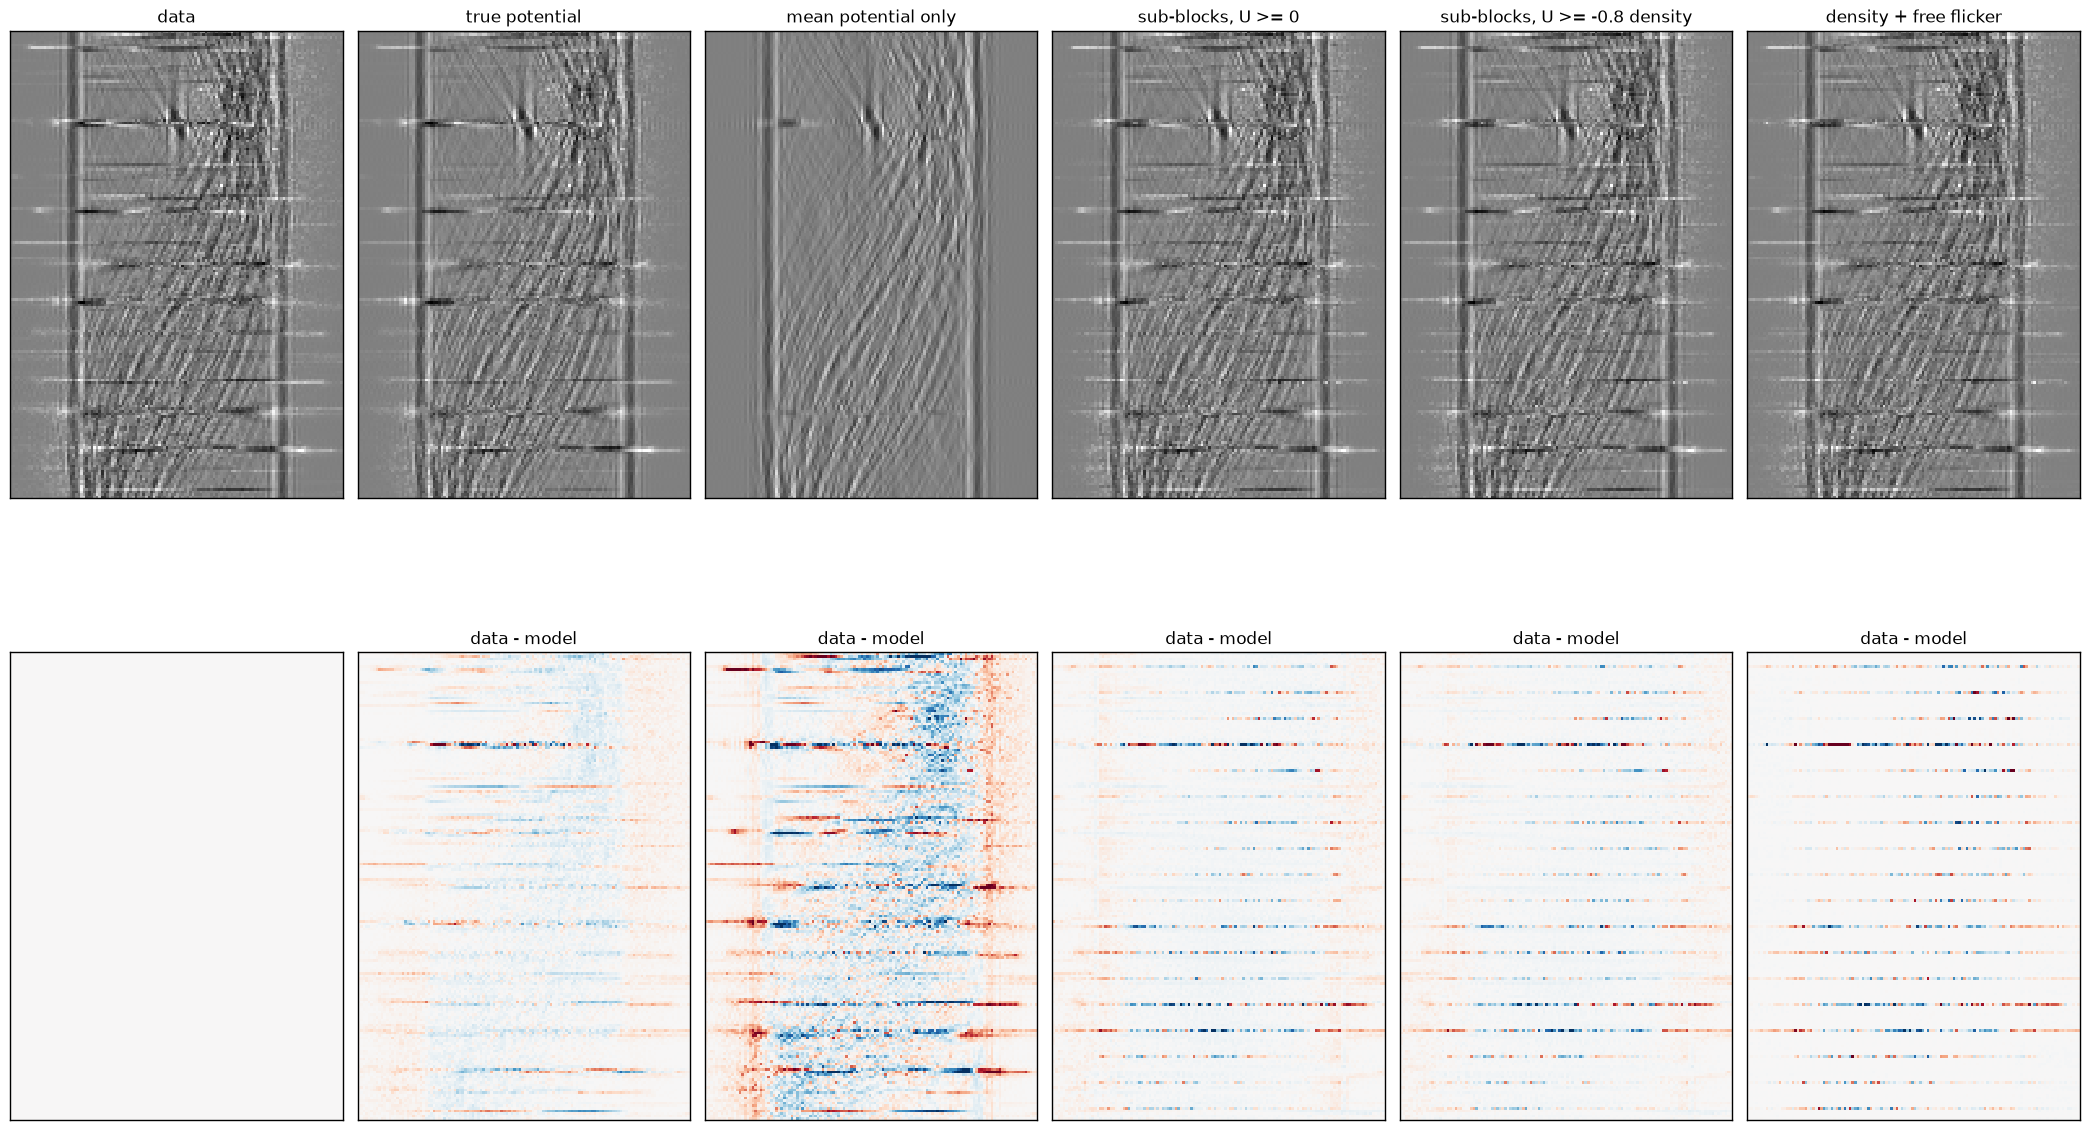

In [5]:
d = sims["fewAm"]
r = {"true potential": truth["fewAm"], **res["fewAm"]}
data = d["I_coarse"]
crop = slice(data.shape[1] // 2 - 64, data.shape[1] // 2 + 64)
held = np.arange(5, len(data), 10)
cols = ["true potential", "mean potential only", "sub-blocks, U >= 0", "sub-blocks, U >= -0.8 density", "density + free flicker"]
nc = len(cols) + 1
norm_int = {"interval_type": "manual", "vmin": 0.2, "vmax": 1.8}
norm_diff = {"interval_type": "centered", "half_range": 0.5}
show_2d(
    [
        [data[:, crop]] + [r[n]["pred"][:, crop] for n in cols],
        [np.zeros_like(data[:, crop])] + [data[:, crop] - r[n]["pred"][:, crop] for n in cols],
    ],
    norm=[[norm_int] * nc, [norm_diff] * nc],
    cmap=[["gray"] * nc, ["RdBu_r"] * nc],
    title=[["data"] + cols, [""] + ["data - model"] * len(cols)],
    axsize=(3.5, 7),
);

## Held-out tilts, amorphous cap
Each held-out tilt is drawn six rows tall.

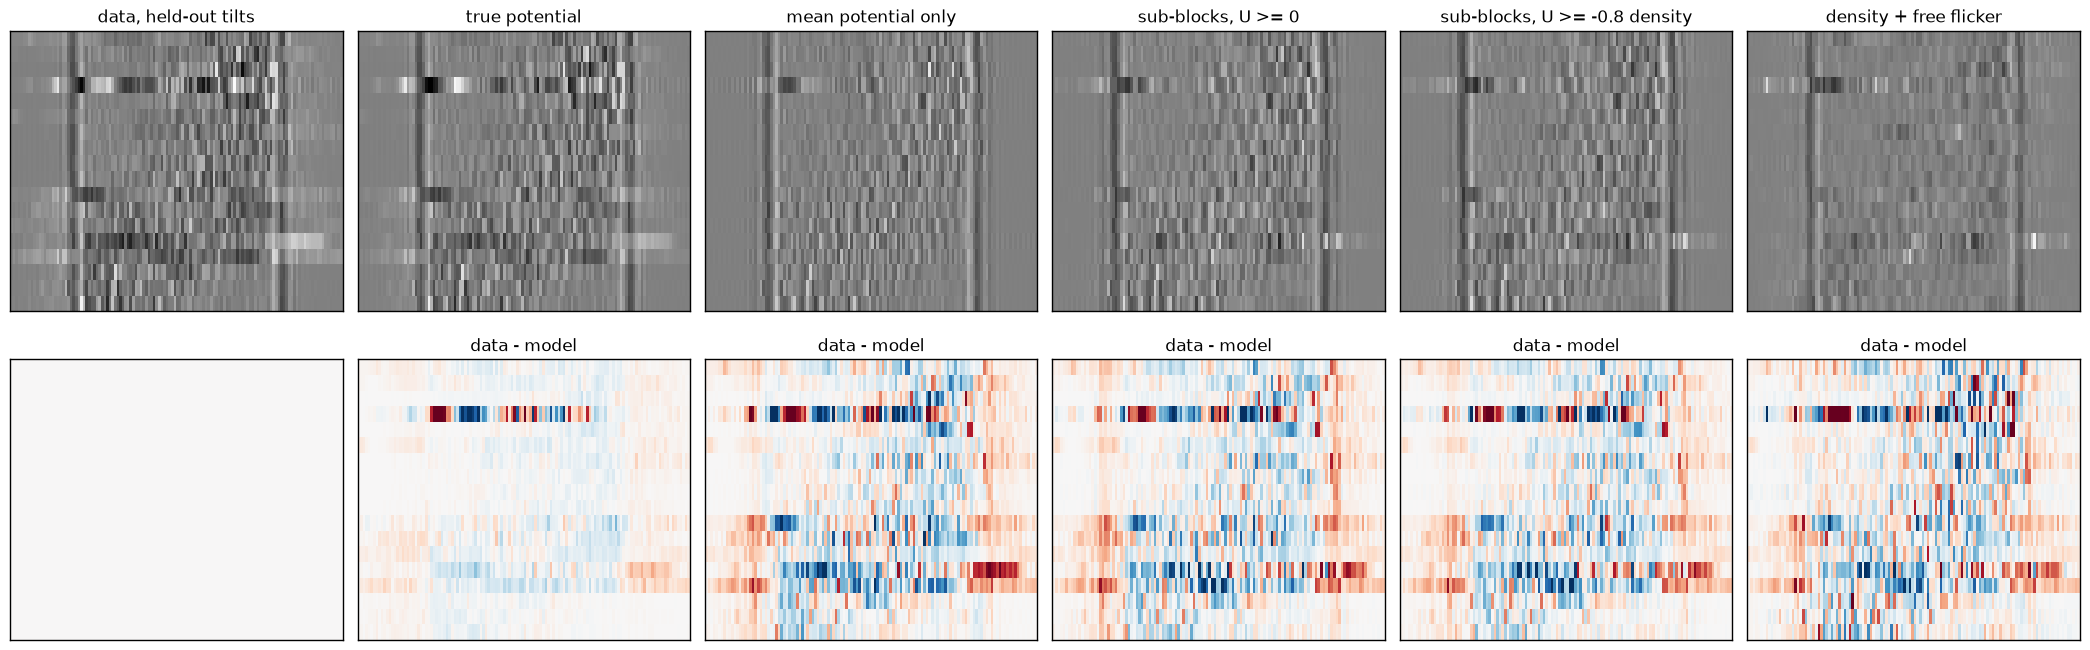

In [6]:
tall = lambda a: np.repeat(a[held][:, crop], 6, axis=0)
show_2d(
    [
        [tall(data)] + [tall(r[n]["pred"]) for n in cols],
        [np.zeros_like(tall(data))] + [tall(data) - tall(r[n]["pred"]) for n in cols],
    ],
    norm=[[norm_int] * nc, [norm_diff] * nc],
    cmap=[["gray"] * nc, ["RdBu_r"] * nc],
    title=[["data, held-out tilts"] + cols, [""] + ["data - model"] * len(cols)],
    axsize=(3.5, 3.5),
);

## Mean potential and flicker-term power, amorphous cap
Flicker-term power: mean square of the part of U above the 2 A band, per voxel. The mean-potential-only model has none.

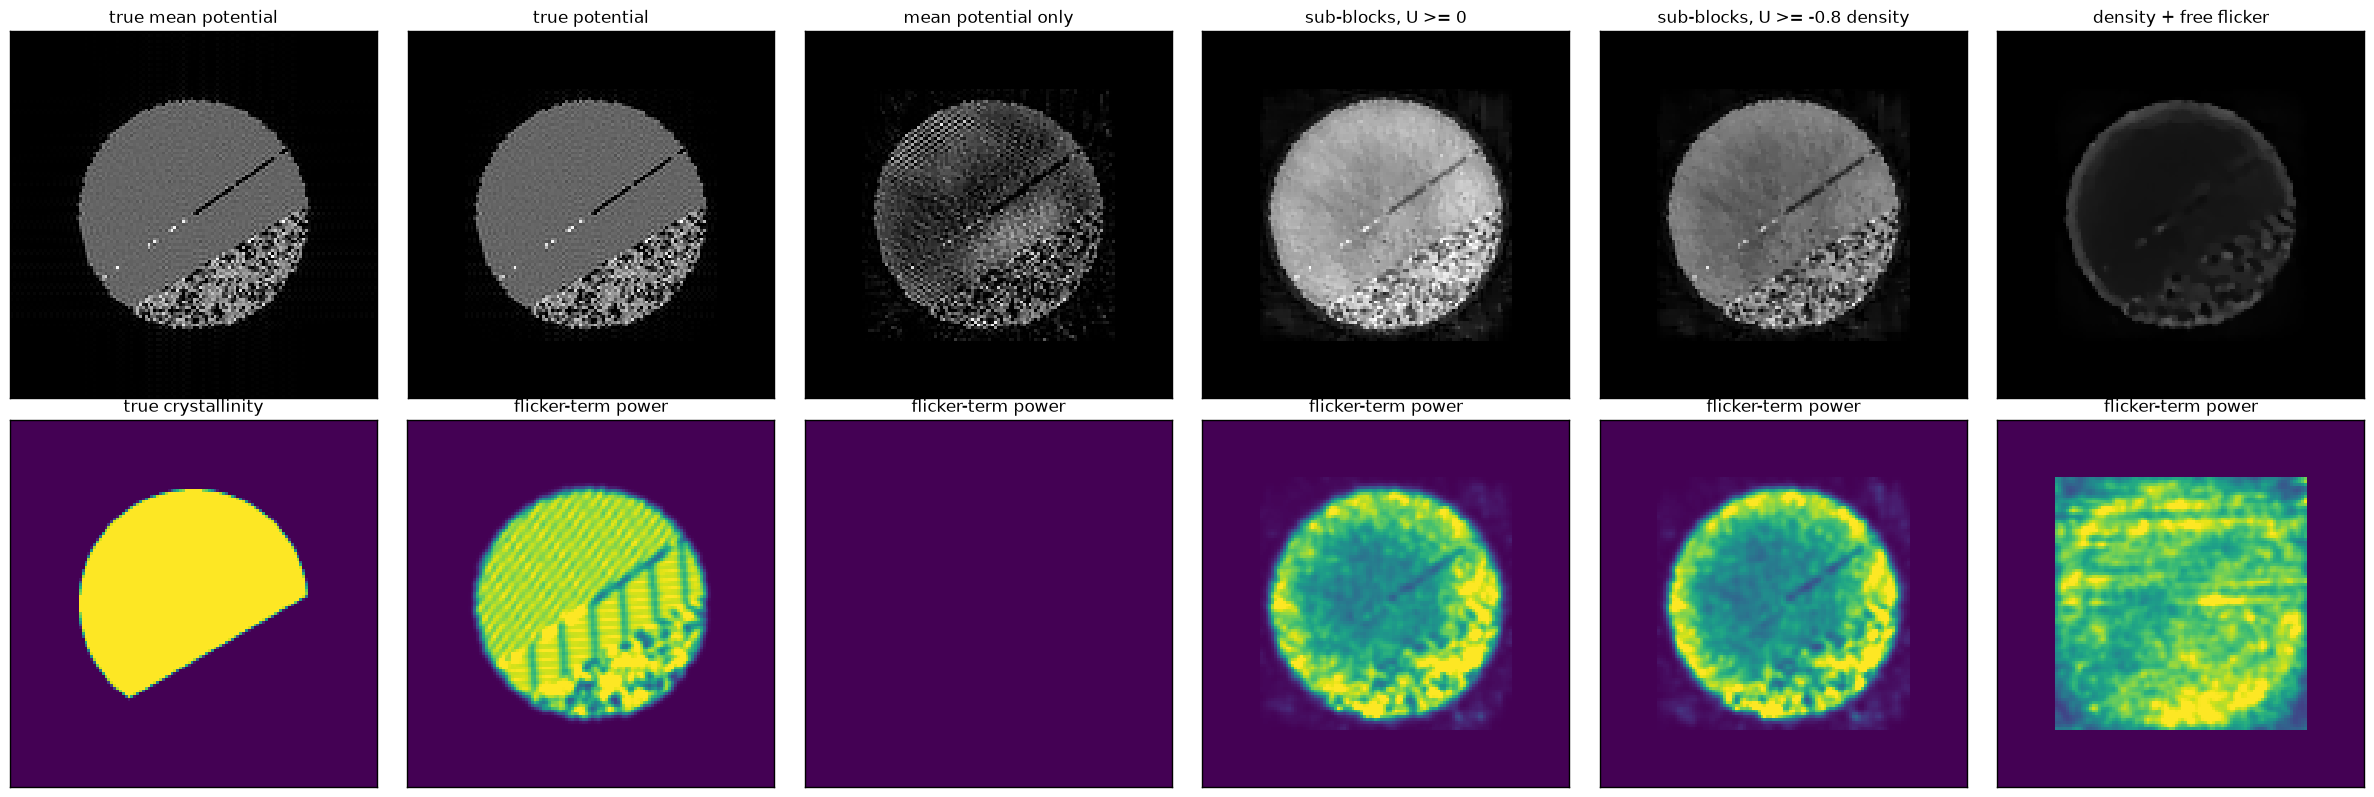

In [7]:
fp = {n: flicker_power(r[n]["U"], m) * (n != "mean potential only") for n in cols}
show_2d(
    [
        [np.flipud(d["vbar"].T)] + [np.flipud(r[n]["vbar"].T) for n in cols],
        [np.flipud(d["cryst"].T)] + [np.flipud(fp[n].T) for n in cols],
    ],
    norm=[[{"interval_type": "manual", "vmin": 0.0, "vmax": 0.05}] * nc,
          [{"interval_type": "manual", "vmin": 0.0, "vmax": 1.0}] + [{"interval_type": "quantile"}] * len(cols)],
    cmap=[["gray"] * nc, ["viridis"] * nc],
    title=[["true mean potential"] + cols, ["true crystallinity"] + ["flicker-term power"] * len(cols)],
);

## Held-out tilts, no amorphous cap
Each held-out tilt is drawn six rows tall.

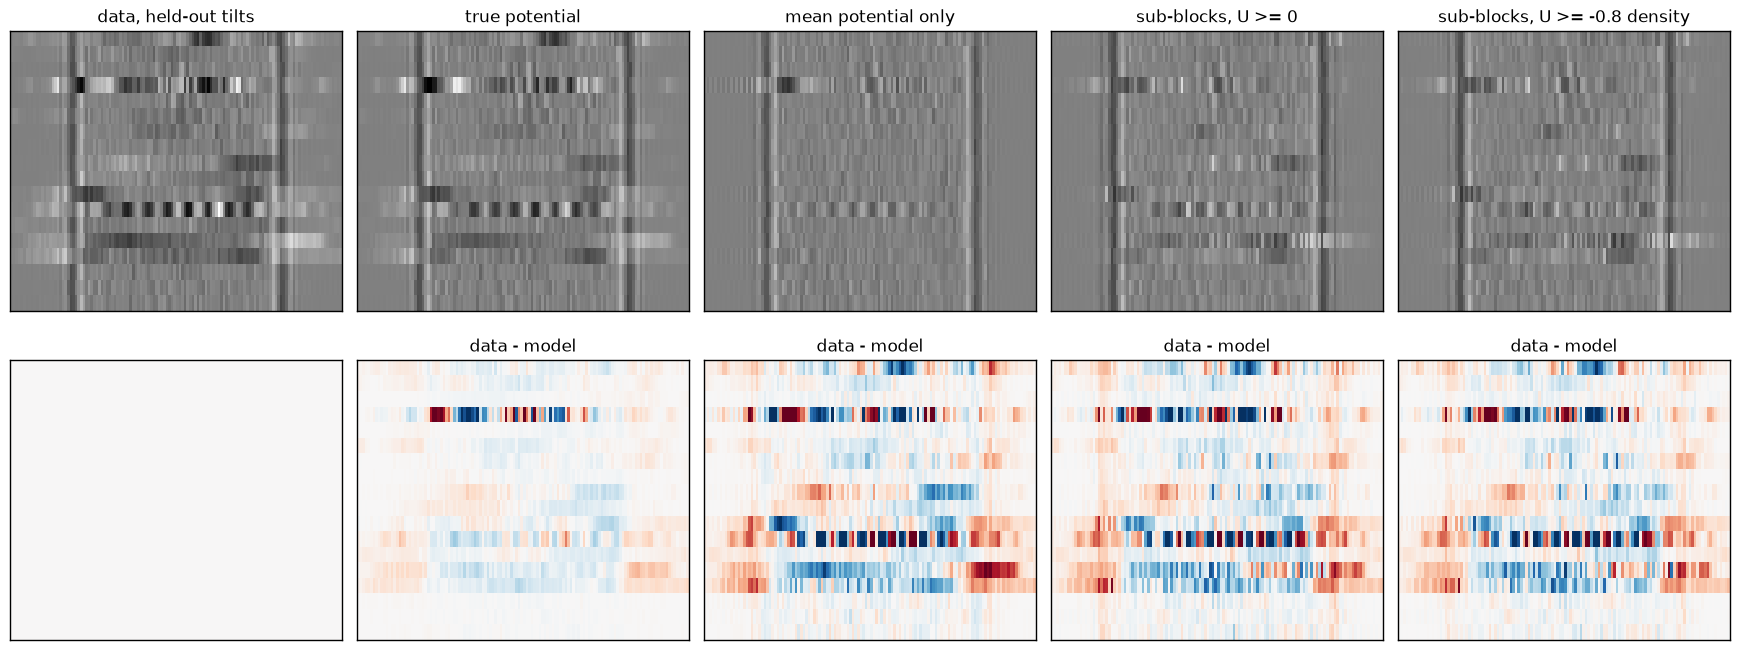

In [8]:
d = sims["fewA"]
r = {"true potential": truth["fewA"], **res["fewA"]}
data = d["I_coarse"]
cols_a = list(r)
show_2d(
    [
        [tall(data)] + [tall(r[n]["pred"]) for n in cols_a],
        [np.zeros_like(tall(data))] + [tall(data) - tall(r[n]["pred"]) for n in cols_a],
    ],
    norm=[[norm_int] * (len(cols_a) + 1), [norm_diff] * (len(cols_a) + 1)],
    cmap=[["gray"] * (len(cols_a) + 1), ["RdBu_r"] * (len(cols_a) + 1)],
    title=[["data, held-out tilts"] + cols_a, [""] + ["data - model"] * len(cols_a)],
    axsize=(3.5, 3.5),
);

## Mean potential, no amorphous cap

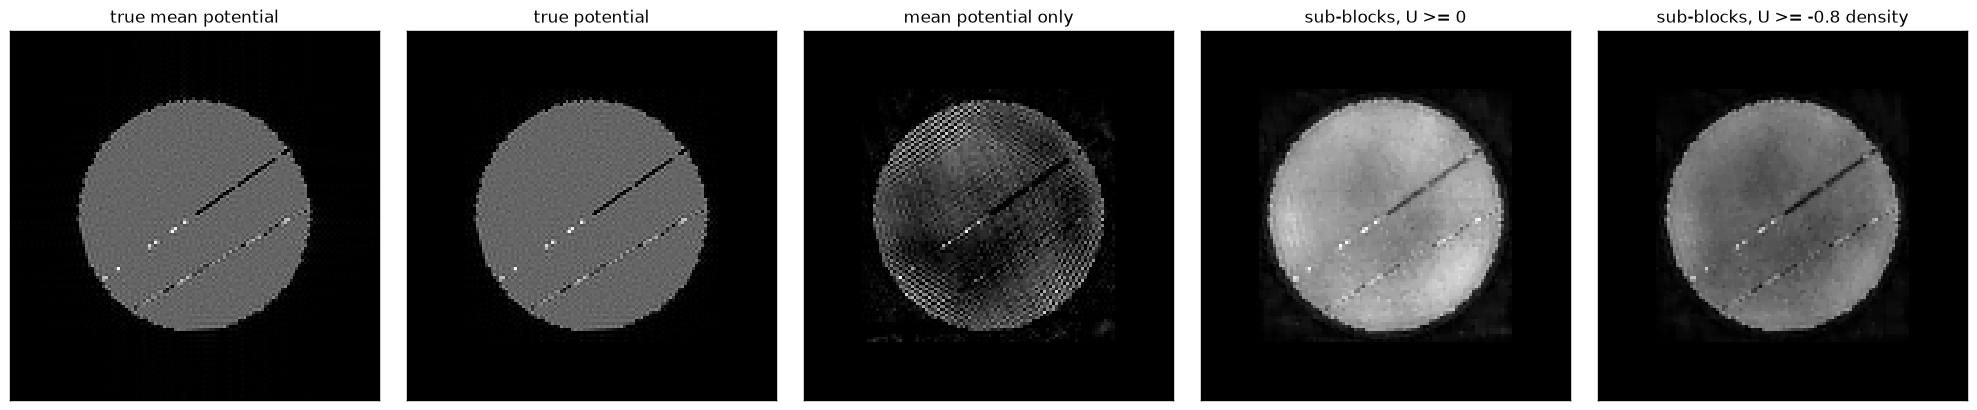

In [9]:
show_2d(
    [np.flipud(d["vbar"].T)] + [np.flipud(r[n]["vbar"].T) for n in cols_a],
    norm={"interval_type": "manual", "vmin": 0.0, "vmax": 0.05},
    cmap="gray",
    title=["true mean potential"] + cols_a,
);